# Guía L2 — El índice sancocho · **Sesión 2: el índice en el tiempo y el duelo de ciudades**

**Cálculo Diferencial — Laboratorio computacional** · Universidad Nacional de Colombia, Sede Manizales

Hoy la olla se pone histórica: años de precios oficiales, los picos con nombre propio, el duelo de ciudades, la apuesta de conmutatividad y la unidad monetaria más seria jamás inventada: **el sancocho**.

**Antes de ejecutar:** predicciones P4 y P5 de la guía, en papel, foto al informe. P5 es la apuesta central del laboratorio — no se la salten, que sin apuesta no hay gloria.

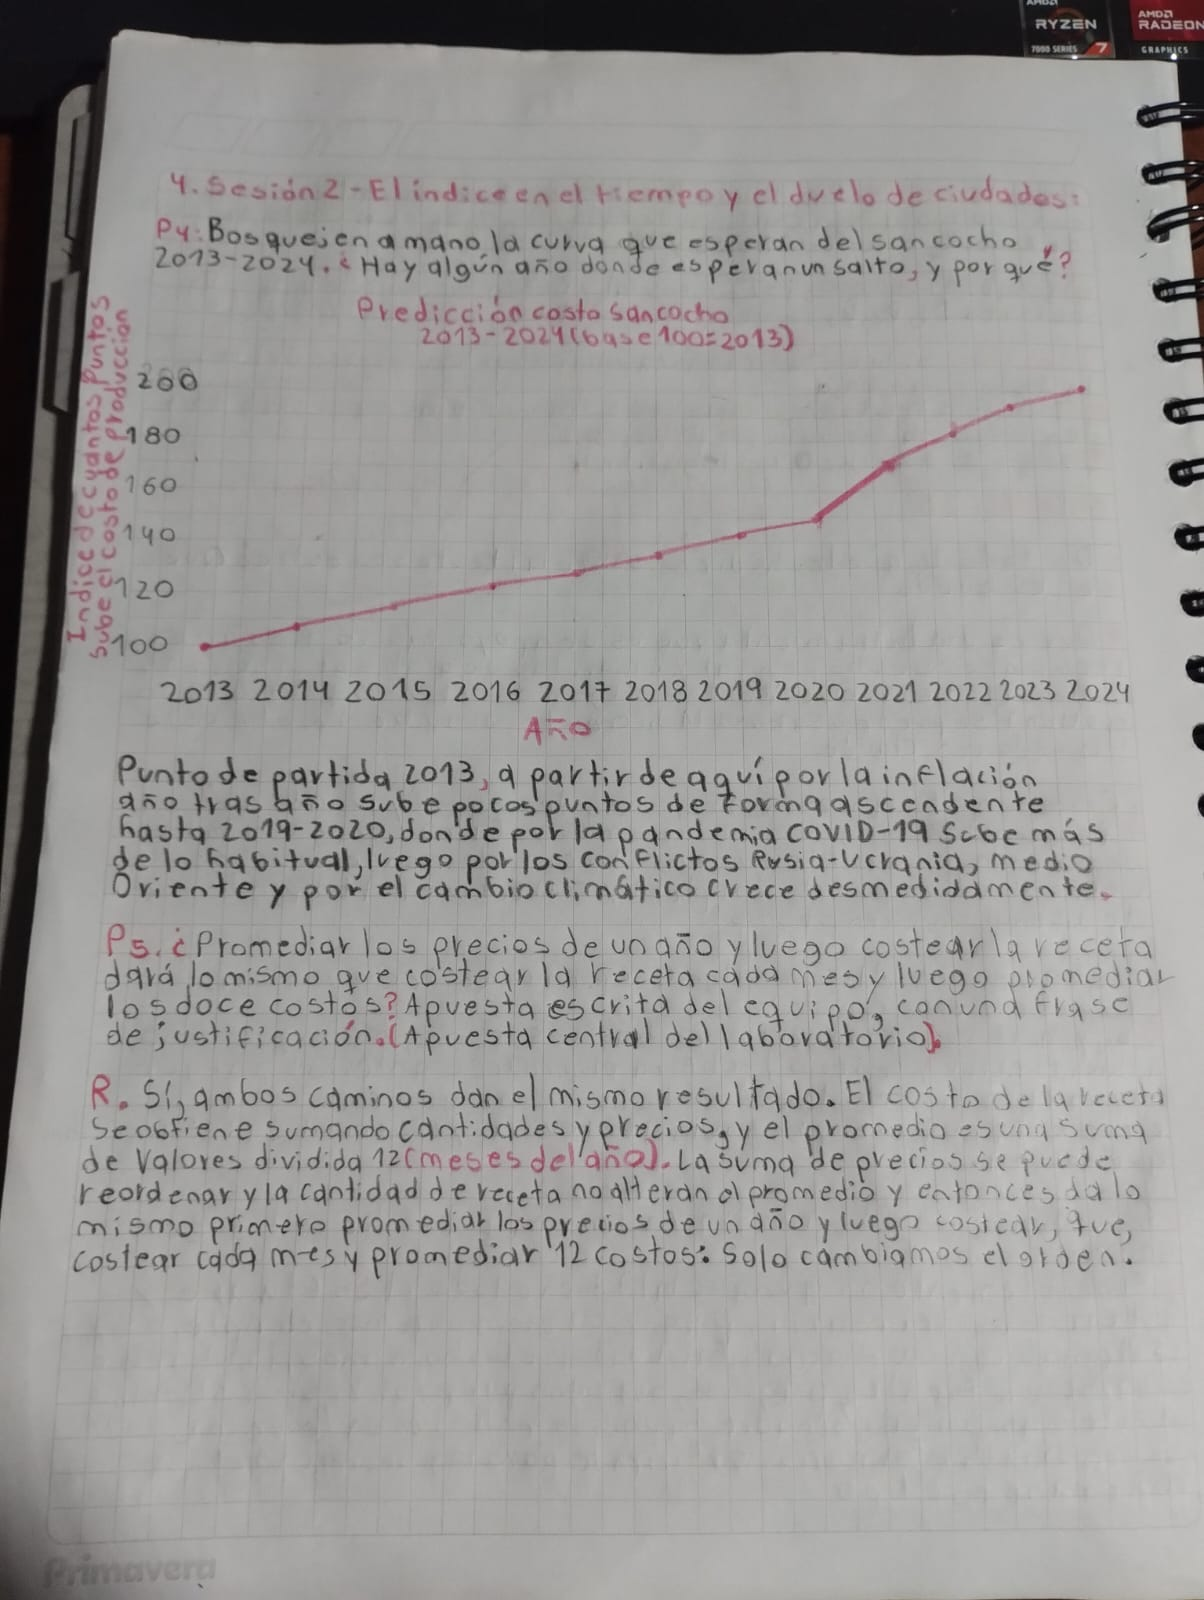

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

RUTA = "https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/main/datos/sipsa_mensual.csv.gz"
df = pd.read_csv(RUTA)

# La receta oficial y el pipeline de la sesión 1 (los reconstruimos aquí para
# que este cuaderno sea autónomo — reproducibilidad ante todo):
RECETA = {
    "Carne de cerdo, espinazo":       1.5,
    "Yuca ICA":                       1.0,
    "Papa capira":                    1.0,
    "Chócolo mazorca":                0.9,
    "Plátano dominico hartón verde":  1.4,
}



def indice_plato(tabla, ciudad, receta):
    "tabla -> serie: costo del plato mes a mes en una ciudad. El pipeline entero, empacado."
    # Si hay varias centrales en la ciudad, se usa su promedio simple por producto y mes.
    t = tabla[(tabla["ciudad"] == ciudad) & (tabla["producto"].isin(receta))]
    p = t.pivot_table(index="fecha", columns="producto", values="precio_kg", aggfunc="mean")
    faltantes = [producto for producto in receta if producto not in p.columns]
    if faltantes:
        raise ValueError(f"{ciudad}: faltan ingredientes de la receta: {faltantes}")
    p = p[list(receta)]
    meses_incompletos = p.index[p.isna().any(axis=1)].to_list()
    if meses_incompletos:
        raise ValueError(f"{ciudad}: receta incompleta en {len(meses_incompletos)} meses; primero revisen la sustitución.")
    return p.mul(pd.Series(receta), axis="columns").sum(axis=1)

print("Pipeline listo. Fíjense: indice_plato RECIBE la tabla, la ciudad y la receta.",
      "Nada global. Cambiar de plato será cambiar un diccionario.")

Pipeline listo. Fíjense: indice_plato RECIBE la tabla, la ciudad y la receta. Nada global. Cambiar de plato será cambiar un diccionario.


---
## 1 · El índice sancocho, 2013 en adelante

Confronten con su P4: ¿la curva que bosquejaron se parece a la real?

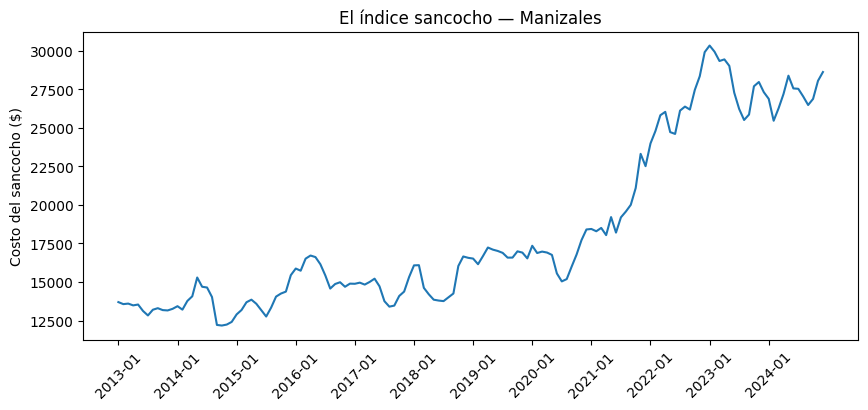

Primer mes (2013-01): $13,695
Último mes (2024-12): $28,634
Variación total: 109.1%


In [ ]:
sancocho_mzl = indice_plato(df, "Manizales", RECETA)

plt.figure(figsize=(10, 4))
plt.plot(range(len(sancocho_mzl)), sancocho_mzl.values)
paso = 12
plt.xticks(range(0, len(sancocho_mzl), paso), sancocho_mzl.index[::paso], rotation=45)
plt.ylabel("Costo del sancocho ($)")
plt.title("El índice sancocho — Manizales")
plt.show()

print(f"Primer mes ({sancocho_mzl.index[0]}): ${sancocho_mzl.iloc[0]:,.0f}")
print(f"Último mes ({sancocho_mzl.index[-1]}): ${sancocho_mzl.iloc[-1]:,.0f}")
print(f"Variación total: {100*(sancocho_mzl.iloc[-1]/sancocho_mzl.iloc[0]-1):.1f}%")


In [ ]:
cambio_pct = sancocho_mzl.pct_change() * 100
cambio_pct.sort_values(ascending=False).head(10)

,0
fecha,
2018-10,12.533326
2021-11,10.512399
2014-05,8.659319
2015-12,7.433481
2023-10,7.096642
2022-01,6.544413
2017-12,6.532157
2021-05,6.486295
2022-07,6.148383


In [ ]:
import pandas as pd

meses = ["2018-09", "2018-10", "2021-10", "2021-11"]
sub = df[(df["ciudad"] == "Manizales") & (df["fecha"].isin(meses))]
precios = sub.groupby(["producto", "fecha"])["precio_kg"].mean().unstack()
precios = precios.loc[list(RECETA.keys())]          # solo los ingredientes de la receta
aporte = precios.mul(pd.Series(RECETA), axis=0)     # precio × kg = aporte en pesos
aporte

fecha,2018-09,2018-10,2021-10,2021-11
producto,,,,
"Carne de cerdo, espinazo",10000.5,11125.5,16000.5,17500.5
Yuca ICA,1708.0,1864.0,1562.0,1924.0
Papa capira,685.0,870.0,1122.0,1379.0
Chócolo mazorca,629.1,634.5,720.0,846.0
Plátano dominico hartón verde,1230.6,1545.6,1698.2,1671.6


**Pico 1: Octubre de 2018 (+12,5 % frente a Septiembre; de \$14.253 a \$16.040).**
Hipótesis: El salto combina el encarecimiento del espinazo, el ingrediente de mayor peso en el costo, con un alza fuerte de papa y plátano, asociada al fin de las cosechas de papa y a una menor oferta de tubérculos.
Evidencia: En Manizales el espinazo aportó ≈63 % del aumento en pesos (+\$1.125), mientras la papa capira (+27 %) y el plátano (+25,6 %) subieron más en porcentaje. El DANE reportó alzas de papas y yuca ICA en octubre de 2018 y el fin de la temporada de cosecha de papa capira en varias regiones (SIPSA, comunicado de Octubre de 2018).


**Pico 2: Noviembre de 2021 (+10,5 % frente a Octubre; de \$21.103 a \$23.321).**
Hipótesis: El alza viene del espinazo y de un salto de los tubérculos (yuca y papa), probablemente por lluvias que dificultaron la cosecha; el plátano no influyó este mes.
Evidencia: el espinazo aportó ≈68 % del aumento en pesos (+\$1.500); yuca (+23,2 %), papa (+22,9 %) y chócolo (+17,5 %) subieron más en porcentaje, y el plátano bajó 1,6 %. El DANE reportó alzas de papa negra y yuca en noviembre de 2021 y, en la parte de papa, lluvias que afectaron la recolección (SIPSA, comunicado de Noviembre de 2021).


---
## 2 · El duelo de ciudades (y el problema de la sustitución)

El sancocho "igual" no existe entre ciudades: el conjunto oficial obliga a decidir **equivalencias** de variedades y cortes. Además, cuando hay varias centrales en una ciudad, `indice_plato` usa el promedio simple de sus observaciones disponibles por producto y mes. El cuaderno trae una receta base que funciona los 144 meses; no es una verdad culinaria. Ambas son decisiones de modelación: defiéndanlas.

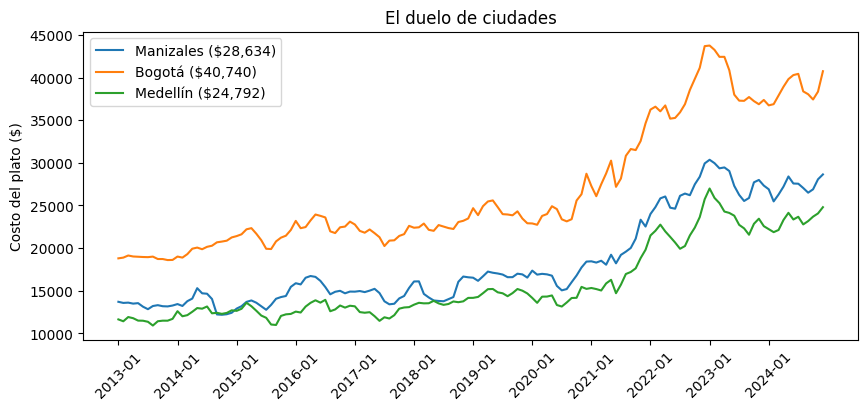

,inicio,final,aumento en pesos,aumento porcentual
Manizales,13695.0,28634.0,14939.0,109.1
Bogotá,18791.0,40740.0,21949.0,116.8
Medellín,11631.0,24792.0,13161.0,113.2


In [ ]:
# ✏️ Ejercicio 1 — Revisen las equivalencias y, si las cambian, defiendan la decisión.
# Pista: df[(df.ciudad=="Bogotá") & (df.producto.str.contains("yuca", case=False))]["producto"].unique()

RECETA_BOGOTA = {
    "Carne de cerdo, costilla":    1.5,   # sustitución del espinazo
    "Yuca llanera":               1.0,
    "Papa parda pastusa":         1.0,
    "Chócolo mazorca":            0.9,
    "Plátano hartón verde":       1.4,
}

RECETA_MEDELLIN = {
    "Carne de cerdo, espinazo":  1.5,
    "Yuca criolla":              1.0,   # sustitución de Yuca ICA
    "Papa capira":               1.0,
    "Chócolo mazorca":           0.9,
    "Plátano hartón verde":      1.4,   # sustitución del dominico hartón
}

series = {
    "Manizales": sancocho_mzl,
    "Bogotá":    indice_plato(df, "Bogotá", RECETA_BOGOTA),
    "Medellín":  indice_plato(df, "Medellín", RECETA_MEDELLIN),
}

plt.figure(figsize=(10, 4))
for ciudad, s in series.items():
    plt.plot(range(len(s)), s.values, label=f"{ciudad} (${s.iloc[-1]:,.0f})")
plt.xticks(range(0, len(sancocho_mzl), 12), sancocho_mzl.index[::12], rotation=45)
plt.ylabel("Costo del plato ($)")
plt.title("El duelo de ciudades")
plt.legend()
plt.show()

comparacion = pd.DataFrame({
    ciudad: {"inicio": serie.iloc[0], "final": serie.iloc[-1]}
    for ciudad, serie in series.items()
}).T
comparacion["aumento en pesos"] = comparacion["final"] - comparacion["inicio"]
comparacion["aumento porcentual"] = 100 * (comparacion["final"] / comparacion["inicio"] - 1)
comparacion.round({"inicio": 0, "final": 0, "aumento en pesos": 0, "aumento porcentual": 1})

In [ ]:
años = 143 / 12   # de 2013-01 a 2024-12
for ciudad, s in series.items():
    anual = s.groupby(s.index.astype(str).str[:4]).mean()
    pct_anual = 100 * (anual.iloc[-1] / anual.iloc[0] - 1)
    tasa = 100 * ((s.iloc[-1] / s.iloc[0]) ** (1 / años) - 1)
    print(ciudad, "| promedio 2024 vs 2013:", round(pct_anual, 1), "% | tasa anual:", round(tasa, 1), "%")

Manizales | promedio 2024 vs 2013: 104.2 % | tasa anual: 6.4 %
Bogotá | promedio 2024 vs 2013: 105.0 % | tasa anual: 6.7 %
Medellín | promedio 2024 vs 2013: 102.2 % | tasa anual: 6.6 %


In [ ]:
recetas = {"Manizales": RECETA, "Bogotá": RECETA_BOGOTA, "Medellín": RECETA_MEDELLIN}
roles = ["Carne", "Yuca", "Papa", "Chócolo", "Plátano"]

cols = {}
for ciudad, rec in recetas.items():
    sub = df[(df["ciudad"] == ciudad) & (df["fecha"] == "2024-12") & (df["producto"].isin(rec.keys()))]
    p = sub.groupby("producto")["precio_kg"].mean().reindex(list(rec.keys()))
    cols[ciudad] = p.values * list(rec.values())     # precio × kg = aporte en pesos

res = pd.DataFrame(cols, index=roles)
res.loc["Total"] = res.sum()
res.round(0)

,Manizales,Bogotá,Medellín
Carne,20250.0,31869.0,15210.0
Yuca,1377.0,1860.0,1828.0
Papa,2133.0,1796.0,2389.0
Chócolo,1146.0,1436.0,1622.0
Plátano,3728.0,3779.0,3742.0
Total,28634.0,40740.0,24792.0


**Tabla de equivalencias:**

| Ingrediente | Manizales | Bogotá | Medellín |
|---|---|---|---|
| Carne de cerdo | espinazo | costilla | espinazo |
| Yuca | Yuca ICA | yuca llanera | yuca criolla |
| Papa | papa capira | papa parda pastusa | papa capira |
| Plátano | dominico hartón | hartón verde | hartón verde |

El chócolo (mazorca) se conserva igual en las tres ciudades.

**Defensa de las equivalencias:** Cada ingrediente se cambió por la variedad o el corte que cumple el mismo papel en el plato y que se vende en la central de esa ciudad, con las mismas cantidades en kg. Así comparamos el mismo tipo de plato y no productos idénticos, que no existen entre ciudades. El costo es que la diferencia exacta de precios depende de la sustitución, por eso confiamos más en el ritmo de crecimiento.

**¿Dónde es más caro el almuerzo y por cuánto?** En Bogotá, durante todo el período. En diciembre de 2024 cuesta \$40.740, contra \$28.634 en Manizales y \$24.792 en Medellín (la más barata).

**¿Las curvas suben al mismo ritmo?** Casi. Las tres tienen la misma forma (subida lenta hasta 2020, subida fuerte en 2021-2022 y máximo a finales de 2022) y crecen a tasas anuales parecidas: 6,4 % Manizales, 6,6 % Medellín y 6,7 % Bogotá.

**¿Dónde subió más?** En pesos: Bogotá (\$21.949), Manizales (\$14.939) y Medellín (\$13.161). En porcentaje: Bogotá (116,8 %), Medellín (113,2 %) y Manizales (109,1 %). Con promedios anuales (2024 vs 2013), el orden es Bogotá 105 %, Manizales 104,2 % y Medellín 102,2 %: Manizales y Medellín están casi empatadas. Reportamos el porcentaje porque las ciudades parten de niveles distintos y así comparamos el ritmo sin que pese el punto de partida. Los pesos son un complemento que muestra el impacto en el bolsillo.

In [ ]:
print(RECETA)

{'Carne de cerdo, espinazo': 1.5, 'Yuca ICA': 1.0, 'Papa capira': 1.0, 'Chócolo mazorca': 0.9, 'Plátano dominico hartón verde': 1.4}


---
## 3 · La apuesta central: ¿conmutan?

P5 sobre la mesa. Dos caminos para el "costo típico anual" del sancocho:

- **Camino A:** promediar los 12 precios del año de cada ingrediente → costear la receta una vez.
- **Camino B:** costear la receta mes a mes → promediar los 12 costos.

¿Dan lo mismo? Primero su apuesta escrita, luego el juez:

**Nuestra apuesta escrita:** Sí, ambos caminos dan el mismo resultado. El costo de la receta es una suma de cantidades por precios (cada ingrediente aporta cantidad × precio), y el promedio de un año es una suma de 12 valores dividida entre 12. Ambas operaciones son **lineales**: la suma se puede reordenar y las cantidades de la receta, que son constantes, salen del promedio sin alterarlo. Por eso promediar primero los precios del año y luego costear equivale a costear cada mes y luego promediar los 12 costos: solo cambiamos el orden de operaciones que se pueden intercambiar.

**JUEZ-CONJETURA DE IA(GEMINI)**: ¿Por qué da lo mismo? (Explicación matemática): Este fenómeno se debe a una propiedad fundamental de las matemáticas: La propiedad distributiva de la multiplicación y la linealidad de las sumas y promedios.Imagina que tu receta tiene dos ingredientes ($A$ y $B$).Método 1 (Costear cada mes y promediar):
Calculas el costo total de la receta en enero ($Q_A \cdot P_{A,\text{ene}} + Q_B \cdot P_{B,\text{ene}}$), luego en febrero, y así sucesivamente hasta diciembre. Al final, sumas los 12 costos y divides entre 12.Método 2 (Promediar precios y luego costear):
Calculas el precio promedio anual del ingrediente $A$ ($\bar{P}_A$) y del ingrediente $B$ ($\bar{P}_B$). Luego multiplicas esas cantidades fijas por sus respectivos precios promedio: $Q_A \cdot \bar{P}_A + Q_B \cdot \bar{P}_B$.Debido a que las cantidades ($Q_A$ y $Q_B$) son constantes, sacarle el promedio a los precios antes de multiplicar o después de multiplicar es exactamente lo mismo. Algebraicamente, sacar una constante de un promedio funciona así:
$$\text{Promedio}(Q \times P) = Q \times \text{Promedio}(P)$$¿Cuándo no daría lo mismo?: Solo dejaría de dar el mismo resultado si las cantidades cambian de un mes a otro en función de los precios (por ejemplo, si cocinas más cantidad de la receta precisamente en los meses donde los ingredientes están más baratos).

In [ ]:
AÑO = "2016"
mzl = df[(df["ciudad"] == "Manizales") & (df["producto"].isin(RECETA))]
anual = mzl[mzl["fecha"].str.startswith(AÑO)]

# Camino A: promediar precios, luego costear
precios_promedio = anual.groupby("producto")["precio_kg"].mean()
camino_A = sum(RECETA[p] * precios_promedio[p] for p in RECETA)

# Camino B: costear cada mes, luego promediar
camino_B = indice_plato(df, "Manizales", RECETA)
camino_B = camino_B[camino_B.index.str.startswith(AÑO)].mean()

print(f"Camino A (promediar → costear): ${camino_A:,.2f}")
print(f"Camino B (costear → promediar): ${camino_B:,.2f}")
print(f"Diferencia: ${abs(camino_A - camino_B):.6f}")

Camino A (promediar → costear): $15,587.53
Camino B (costear → promediar): $15,587.53
Diferencia: $0.000000


In [ ]:
AÑO = "2022"
mzl = df[(df["ciudad"] == "Manizales") & (df["producto"].isin(RECETA))]
anual = mzl[mzl["fecha"].str.startswith(AÑO)]

# Camino A: promediar precios, luego costear
precios_promedio = anual.groupby("producto")["precio_kg"].mean()
camino_A = sum(RECETA[p] * precios_promedio[p] for p in RECETA)

# Camino B: costear cada mes, luego promediar
camino_B = indice_plato(df, "Manizales", RECETA)
camino_B = camino_B[camino_B.index.str.startswith(AÑO)].mean()

print(f"Camino A (promediar → costear): ${camino_A:,.2f}")
print(f"Camino B (costear → promediar): ${camino_B:,.2f}")
print(f"Diferencia: ${abs(camino_A - camino_B):.6f}")

Camino A (promediar → costear): $26,207.68
Camino B (costear → promediar): $26,207.67
Diferencia: $0.000000


**Veredicto:** El código confirmó la apuesta: en 2016 (Manizales) el Camino A y el Camino B dieron \$15.587,53, con diferencia 0. La IA acertó el resultado y también la razón correcta (la linealidad: las cantidades constantes salen del promedio). Su advertencia sobre cantidades variables es válida, pero no aplica a nuestra receta; lo que rompe la conmutatividad aquí son operaciones no lineales como la mediana, que veremos a continuación.

In [ ]:
# 🖍️ Ejercicio 2 — Rompan la magia.
# Repitan los dos caminos usando la MEDIANA en lugar del promedio.
# ¿Siguen dando lo mismo? ¿Y si antes de promediar eliminan el 5% de precios más caros?

import pandas as pd

# Precios mensuales de cada ingrediente en el año (promedio simple entre mercados, como hace indice_plato)
p_mes = anual.groupby(["fecha", "producto"])["precio_kg"].mean().unstack()
p_mes = p_mes[list(RECETA.keys())].dropna()
q = pd.Series(RECETA)
costo_mes = (p_mes * q).sum(axis=1)          # costo de cada mes

def recorte5(s):                              # descarta el 5 % más alto y promedia el resto
    return s[s <= s.quantile(0.95)].mean()

# --- MEDIANA ---
camino_A_mediana = (p_mes.median() * q).sum()     # mediana de precios -> costear
camino_B_mediana = costo_mes.median()             # costear cada mes -> mediana de costos

# --- RECORTE DEL 5 % ---
camino_A_recorte = (p_mes.apply(recorte5) * q).sum()
camino_B_recorte = recorte5(costo_mes)

for nombre, a, b in [("Mediana", camino_A_mediana, camino_B_mediana),
                     ("Recorte 5 %", camino_A_recorte, camino_B_recorte)]:
    print(f"{nombre}: A = ${a:,.2f} | B = ${b:,.2f} | diferencia = ${abs(a - b):,.2f} ({100 * abs(a - b) / b:.2f} %)")

# 🖍️ Moraleja (escríbanla como comentario): los dos caminos coinciden con el promedio
# porque la receta es LINEAL (suma de cantidad × precio) y el promedio también lo es; con la mediana se rompe
# porque la mediana NO es lineal: la mediana de una suma no es la suma de las medianas.

Mediana: A = $25,882.90 | B = $26,087.90 | diferencia = $205.00 (0.79 %)
Recorte 5 %: A = $25,733.20 | B = $25,869.78 | diferencia = $136.58 (0.53 %)


**Ruptura de la conmutatividad (Manizales, 2016):** Con el promedio ambos caminos dieron \$15.587,53 (diferencia 0). Con la mediana, A = \$15.643,55 y B = \$15.580,50 (diferencia \$63,05, 0,40 %); con el recorte del 5 %, A = \$15.451,83 y B = \$15.484,67 (diferencia \$32,84, 0,21 %). La diferencia es pequeña en este año, pero ya no es cero: el orden de los pasos importa.

**¿Por qué?** El promedio y el costo (suma de cantidad × precio) son operaciones lineales, y las operaciones lineales conmutan: las cantidades constantes salen del promedio. La mediana y el recorte no son lineales: el mes que queda "en el medio" o "arriba" cambia de un ingrediente a otro, y no coincide con el mes que queda en el medio del costo total. Por eso la mediana de una suma no es la suma de las medianas.

---
## 4 · El camino de regreso: la unidad sancocho

Del costo total del plato no se puede recuperar el precio del plátano — la suma colapsa infinitas combinaciones en un número (no inyectiva: información que muere). Pero hay una conversión que sí tiene camino de regreso perfecto:

In [ ]:
VALOR_SANCOCHO = float(sancocho_mzl.iloc[-1])   # 1 sancocho = costo del último mes del congelado

def a_sancochos(pesos):
    return pesos / VALOR_SANCOCHO

def a_pesos(sancochos):
    return sancochos * VALOR_SANCOCHO

# La prueba de fuego de una inversa: ida y vuelta = quedarse quieto.
print("¿a_pesos(a_sancochos(x)) == x?  →", a_pesos(a_sancochos(123456.0)))

# ✏️ Ejercicio 3 — Conviertan a sancochos: el salario mínimo de ese año, la matrícula,
# y la mesada (o el presupuesto mensual de comida) de alguien del equipo que quiera confesarla.
SALARIO_MINIMO = 0
# Salarios mínimos mensuales legales (SMMLV, sin auxilio de transporte)
# Fuentes: 2013 -> $589.500 (decreto de dic. 2012, Noticias RCN / EFE); 2024 -> $1.300.000 (Decreto 2292 de 2023)
SMMLV_2013 = 589_500
SMMLV_2024 = 1_300_000

# Matrícula y mesada: pongan sus valores reales y documenten la fuente (recibo de matrícula, etc.)
MATRICULA = 153_000     # <- completar
MESADA = 500_000       # <- completar (mesada o presupuesto mensual de comida de alguien del equipo)

print(f"Salario mínimo 2024: {a_sancochos(SMMLV_2024):.1f} sancochos")
print(f"Matrícula: {a_sancochos(MATRICULA):.1f} sancochos")
print(f"Mesada: {a_sancochos(MESADA):.1f} sancochos")

# --- La pregunta incómoda ---
# (a) Con la unidad fija (sancocho de dic-2024): mezcla pesos de 2013 con pesos de 2024
print("\n(a) Unidad fija:", round(a_sancochos(SMMLV_2013), 1), "vs", round(a_sancochos(SMMLV_2024), 1))

# (b) Comparación justa: cada salario / costo del sancocho de ESE año (promedio anual)
costo_2013 = sancocho_mzl[sancocho_mzl.index.astype(str).str.startswith("2013")].mean()
costo_2024 = sancocho_mzl[sancocho_mzl.index.astype(str).str.startswith("2024")].mean()
print("(b) Mismo año:", round(SMMLV_2013 / costo_2013, 1), "vs", round(SMMLV_2024 / costo_2024, 1))      # ← búsquenlo (¡documenten la fuente!)
# print(f"El salario mínimo equivale a {a_sancochos(SALARIO_MINIMO):.1f} sancochos")

# 🗣️ ¿Y la pregunta incómoda: el salario mínimo de 2013 alcanzaba para más o menos
# sancochos que el del último año del dataset? Calcúlenlo. Eso — poder adquisitivo
# medido en almuerzos — es economía seria con matemáticas de primer semestre.

¿a_pesos(a_sancochos(x)) == x?  → 123456.00000000001
Salario mínimo 2024: 45.4 sancochos
Matrícula: 5.3 sancochos
Mesada: 17.5 sancochos

(a) Unidad fija: 20.6 vs 45.4
(b) Mismo año: 44.2 vs 47.8


**La unidad sancocho:** 1 sancocho = \$28.634 (costo de dic-2024 en Manizales). La conversión pesos ↔ sancochos es una biyección (dividir o multiplicar por una constante positiva), y la prueba de ida y vuelta lo confirma (el 0,00000000001 de diferencia es solo redondeo del computador). Convertido: el salario mínimo de 2024 equivale a 45,4 sancochos; la matrícula, a 5,3 sancochos; la mesada, a 17,5 sancochos.

**Poder adquisitivo:** dividir el salario de 2013 entre el sancocho de 2024 mezclaría pesos de épocas distintas (daría 20,6 contra 45,4, una comparación engañosa). Comparando cada salario con el costo del sancocho de su propio año, el salario mínimo de 2013 (\$589.500) alcanzaba para 44,2 sancochos y el de 2024 (\$1.300.000) para 47,8. El poder adquisitivo medido en almuerzos subió cerca de 8 %(47,8 / 44,2 ≈ 1,08): el salario aumentó más que el precio del sancocho.

---
## 5 · El plato propio (proyecto del equipo)

Cambiar de plato es cambiar un diccionario — esa es la recompensa de haber escrito el pipeline como funciones. Elijan SU plato (ajiaco, mondongo, frijolada, o la receta de su casa con las cantidades que les dicte quien cocina) y construyan su índice.

In [ ]:
for palabra in ["maíz", "maiz", "chócolo", "mazorca"]:
    print(palabra, "->", df[(df.ciudad == "Manizales") &
          (df.producto.str.contains(palabra, case=False))]["producto"].unique())
    d = df[(df.ciudad == "Manizales") & (df.producto == "Chócolo mazorca")]
print(d["fecha"].nunique(), d["fecha"].min(), d["fecha"].max())

maíz -> ['Harina precocida de maíz' 'Maíz amarillo cáscara' 'Maíz blanco trillado']
maiz -> []
chócolo -> ['Chócolo mazorca']
mazorca -> ['Chócolo mazorca']
144 2013-01 2024-12


In [ ]:
candidatos = ["Huevo blanco A", "Huevo blanco AA", "Huevo blanco B", "Huevo blanco extra",
              "Tomate chonto", "Tomate riñón", "Cebolla junca", "Cebolla cabezona blanca"]
for nombre in candidatos:
    d = df[(df.ciudad == "Manizales") & (df.producto == nombre)]
    print(f"{nombre:26} | meses: {d['fecha'].nunique():3} | primero: {d['fecha'].min()} | último: {d['fecha'].max()}")

Huevo blanco A             | meses: 140 | primero: 2013-01 | último: 2024-12
Huevo blanco AA            | meses: 144 | primero: 2013-01 | último: 2024-12
Huevo blanco B             | meses:  61 | primero: 2013-01 | último: 2018-03
Huevo blanco extra         | meses: 144 | primero: 2013-01 | último: 2024-12
Tomate chonto              | meses: 144 | primero: 2013-01 | último: 2024-12
Tomate riñón               | meses:  87 | primero: 2013-01 | último: 2021-09
Cebolla junca              | meses: 144 | primero: 2013-01 | último: 2024-12
Cebolla cabezona blanca    | meses: 144 | primero: 2013-01 | último: 2024-12


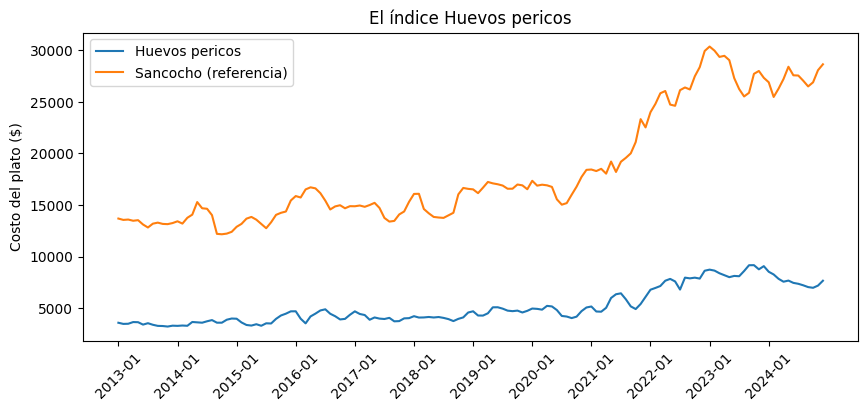

In [ ]:
# ✏️ Ejercicio 4 — Su plato, su índice.
RECETA_PROPIA = {
    "Huevo blanco AA":  12,     # 12 huevos (el DANE da el precio por UNIDAD, no por kg)
    "Tomate chonto":    0.4,    # equivale a 3 tomates hartones medianos
    "Cebolla junca":    0.2,    # equivale a 2 tallos grandes de cebolla larga
    "Chócolo mazorca":  0.15,   # equivale a 1 lata mediana de maíz tierno (aproximación)
}
    # "Producto oficial del DANE": kilos,}
NOMBRE_PLATO = "Huevos pericos"
CIUDAD_PROPIA = "Manizales"

if RECETA_PROPIA:
    mi_indice = indice_plato(df, CIUDAD_PROPIA, RECETA_PROPIA)
    plt.figure(figsize=(10, 4))
    plt.plot(range(len(mi_indice)), mi_indice.values, label=NOMBRE_PLATO)
    plt.plot(range(len(sancocho_mzl)), sancocho_mzl.values, label="Sancocho (referencia)")
    plt.xticks(range(0, len(sancocho_mzl), 12), sancocho_mzl.index[::12], rotation=45)
    plt.ylabel("Costo del plato ($)")
    plt.legend()
    plt.title(f"El índice {NOMBRE_PLATO}")
    plt.show()
    # ¿Su plato se infló más o menos que el sancocho? ¿En qué años se separan las curvas?

Huevos pericos: $3,603 -> $7,674 (x2.13, +113.0 %)
Sancocho: $13,695 -> $28,634 (x2.09, +109.1 %)
       Huevos pericos  Sancocho
fecha                          
2013            100.0     100.0
2014            105.2     101.4
2015            110.2     102.9
2016            124.6     117.0
2017            118.6     108.8
2018            119.1     112.5
2019            136.6     125.8
2020            136.5     124.8
2021            159.1     147.9
2022            220.1     196.7
2023            248.7     210.2
2024            219.4     204.2


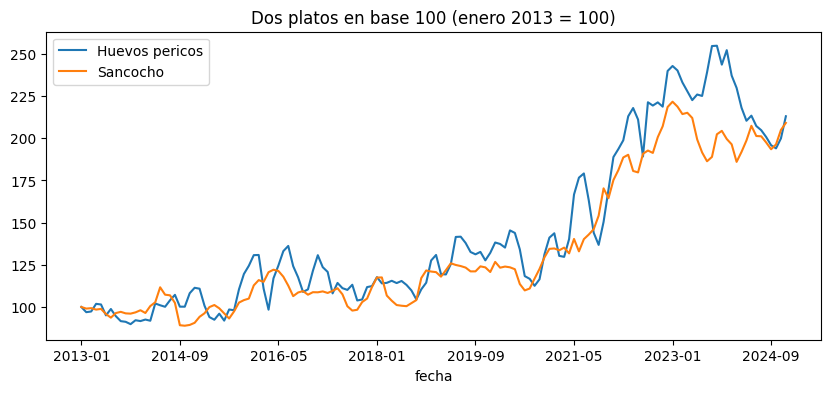

In [ ]:
import pandas as pd

comp = pd.DataFrame({NOMBRE_PLATO: mi_indice, "Sancocho": sancocho_mzl}).dropna()

# 1) Cuánto subió cada plato (enero 2013 -> diciembre 2024)
for c in comp.columns:
    ini, fin = comp[c].iloc[0], comp[c].iloc[-1]
    print(f"{c}: ${ini:,.0f} -> ${fin:,.0f} (x{fin/ini:.2f}, +{100*(fin/ini-1):.1f} %)")

# 2) Base 100 (enero 2013 = 100)
base100 = 100 * comp / comp.iloc[0]
base100.plot(figsize=(10, 4), title="Dos platos en base 100 (enero 2013 = 100)")

# 3) Promedios anuales con 2013 = 100 (más estable)
anual = comp.groupby(comp.index.astype(str).str[:4]).mean()
print((100 * anual / anual.iloc[0]).round(1))

In [ ]:
ult = df[(df.ciudad == "Manizales") & (df.fecha == "2024-12") & (df.producto.isin(RECETA_PROPIA))]
aporte = ult.groupby("producto")["precio_kg"].mean() * pd.Series(RECETA_PROPIA)
print((100 * aporte / aporte.sum()).round(0))

Cebolla junca      23.0
Chócolo mazorca     9.0
Huevo blanco AA    16.0
Tomate chonto      52.0
dtype: float64


In [ ]:
anual = comp.groupby(comp.index.astype(str).str[:4]).mean()
print((100 * anual / anual.iloc[0]).round(1))

       Huevos pericos  Sancocho
fecha                          
2013            100.0     100.0
2014            108.3     101.4
2015            122.3     102.9
2016            133.3     117.0
2017            131.1     108.8
2018            129.5     112.5
2019            142.7     125.8
2020            136.7     124.8
2021            150.8     147.9
2022            208.9     196.7
2023            237.9     210.2
2024            214.0     204.2


In [ ]:
ult = df[(df.ciudad == "Manizales") & (df.fecha == "2024-12") & (df.producto.isin(RECETA_PROPIA))]
aporte = ult.groupby("producto")["precio_kg"].mean() * pd.Series(RECETA_PROPIA)
print((100 * aporte / aporte.sum()).round(0))

Cebolla junca       6.0
Chócolo mazorca     2.0
Huevo blanco AA    77.0
Tomate chonto      14.0
dtype: float64


**Plato propio: huevos pericos (Manizales).**

**Decisiones de modelación:**
- La salchicha no aparece en los datos del DANE para Manizales, así que se reemplazó por maíz tierno.
- Huevo blanco AA: Tiene los 144 meses (A tiene 140 y B solo 61). El DANE reporta su precio por unidad, por eso la cantidad es 12 huevos y no kilos.
- Tomate chonto: Tiene los 144 meses (el riñón solo tiene 87 y la salsa de tomate es un producto procesado).
- Cebolla junca: Equivale a la cebolla larga de la receta y tiene los 144 meses.
- Chócolo mazorca: Es lo más cercano al maíz tierno; el DANE mide mazorca fresca y no maíz enlatado, así que es una aproximación.

**Resultado:** El costo de los huevos pericos pasó de \$3.603 a \$7.674 entre enero de 2013 y diciembre de 2024 (x2,13; +113,0 %), mientras que el sancocho pasó de \$13.695 a \$28.634 (x2,09; +109,1 %). Con promedios anuales (2013 = 100), en 2024 los huevos pericos están en 219,4 y el sancocho en 204,2.

**¿Se inflaron parejo?** Casi. Ambos platos se más que duplicaron y se mueven juntos hasta 2021. Se separan en 2022 y 2023, cuando los huevos pericos suben más (en 2023: 248,7 contra 210,2) y luego bajan. Además, su curva es más irregular que la del sancocho. Para entender la diferencia miramos cuánto pesa cada ingrediente en diciembre de 2024: el huevo aporta 77 % del costo del plato, el tomate 14 %, la cebolla 6 % y el chócolo 2 %. Es decir, el plato depende sobre todo del precio del huevo, que según los boletines del SIPSA responde a la oferta de las granjas avícolas, y en menor medida del tomate y la cebolla, cultivos expuestos al clima (sequías o inundaciones). En el sancocho también domina un solo ingrediente, el espinazo (cerca de 70 a 76 % en los meses de los picos), así que la concentración no explica por sí sola la diferencia. Nuestra hipótesis es que los precios del huevo, el tomate y la cebolla varían más de un mes a otro que el del espinazo.

**Momento 3: Explicar**

**0. Confrontación con mi predicción (P4)**
Datos: Predijimos una subida constante con un salto hacia 2020 (COVID). La curva real pasó de \$13.695 a \$28.634 (x2,09; +109,1 %), con un escalón fuerte en 2021-2022 y sin salto claro en 2020. Con punto de partida en 2013, y a casua y efecto de la inflacion, año tras año sube pocos puntos de forma ascendente hasta 2019-2020 y posteriormente por los conflictos Rusia-Ucrania y medio Oriente, y por el cambio climatico crecia desmedidamente. Pudo validar esto la grafica ya que despues del 2022 sufrio un aumento el costo del sancocho pero a mediados de 2023 se estabilizo un poco y por ello nuestra prediccion fallo porque no subio en todo momento, ademas de que estuvimos fallando los 2 picos por 2018 y 2021.


**1. La apuesta de conmutatividad**
Datos: apostamos que sí dan lo mismo. En Manizales 2016, promediar→costear y costear→promediar dieron \$15.587,53 (diferencia 0). Con la mediana: A = \$15.643,55 y B = \$15.580,50 (diferencia \$63,05; 0,40 %). Con el recorte del 5 %: A = \$15.451,83 y B = \$15.484,67 (diferencia \$32,84; 0,21 %).
JUEZ-CONJETURA DE IA(GEMINI): ¿Por qué da lo mismo? (Explicación matemática): Este fenómeno se debe a una propiedad fundamental de las matemáticas: La propiedad distributiva de la multiplicación y la linealidad de las sumas y promedios.Imagina que tu receta tiene dos ingredientes ( A  y  B ).Debido a que las cantidades ( QA  y  QB ) son constantes, sacarle el promedio a los precios antes de multiplicar o después de multiplicar es exactamente lo mismo.

**2. Invertibilidad del pipeline**

| Paso | ¿Tiene regreso? | Por qué |
|---|---|---|
| `filtrar_ciudad`, `filtrar_mes`, `filtrar_productos` | No | Borran filas: de la salida no se recuperan las demás |
| Promediar centrales con `mean` | No | Muchas combinaciones de precios dan el mismo promedio (100 y 300 dan lo mismo que 200 y 200) |
| `costear` | No | Colapsa muchos precios en un solo número: espinazo \$10.000 + plátano \$1.500 y espinazo \$9.500 + plátano \$2.000 dan ambos \$11.500 |
| Unidades de cocina a kg | Sí, si el factor es fijo | kg = 0,3 × mazorcas, así que mazorcas = kg / 0,3 (aunque el peso real de cada mazorca varía) |
| Pesos a sancochos | Sí | Es una biyección: se divide entre una constante distinta de cero (\$28.634) |

**3. Lectura histórica de los dos picos**
Datos: octubre de 2018 (+12,5 %; \$14.253 → \$16.040): el espinazo explica ≈63 % del aumento en pesos; papa +27 % y plátano +25,6 %. Noviembre de 2021 (+10,5 %; \$21.103 → \$23.321): el espinazo explica ≈68 %; yuca +23,2 %, papa +22,9 %, plátano −1,6 %. Fuente: comunicados SIPSA del DANE de octubre de 2018 y noviembre de 2021.
Pico 1: Octubre de 2018 (+12,5 % frente a Septiembre; de $14.253 a $16.040). Hipótesis: El salto combina el encarecimiento del espinazo, el ingrediente de mayor peso en el costo, con un alza fuerte de papa y plátano, asociada al fin de las cosechas de papa y a una menor oferta de tubérculos. Evidencia: En Manizales el espinazo aportó ≈63 % del aumento en pesos (+$1.125), mientras la papa capira (+27 %) y el plátano (+25,6 %) subieron más en porcentaje. El DANE reportó alzas de papas y yuca ICA en octubre de 2018 y el fin de la temporada de cosecha de papa capira en varias regiones (SIPSA, comunicado de Octubre de 2018).

Pico 2: Noviembre de 2021 (+10,5 % frente a Octubre; de $21.103 a $23.321). Hipótesis: El alza viene del espinazo y de un salto de los tubérculos (yuca y papa), probablemente por lluvias que dificultaron la cosecha; el plátano no influyó este mes. Evidencia: el espinazo aportó ≈68 % del aumento en pesos (+$1.500); yuca (+23,2 %), papa (+22,9 %) y chócolo (+17,5 %) subieron más en porcentaje, y el plátano bajó 1,6 %. El DANE reportó alzas de papa negra y yuca en noviembre de 2021 y, en la parte de papa, lluvias que afectaron la recolección (SIPSA, comunicado de Noviembre de 2021)

**4. Duelo de ciudades**
Datos: en diciembre de 2024 Bogotá \$40.740, Manizales \$28.634 y Medellín \$24.792. Aumento porcentual: Bogotá 116,8 %, Medellín 113,2 %, Manizales 109,1 %. Ritmo anual: 6,7 %, 6,6 % y 6,4 %.
Defensa de las equivalencias: Cada ingrediente se cambió por la variedad o el corte que cumple el mismo papel en el plato y que se vende en la central de esa ciudad, con las mismas cantidades en kg. Así comparamos el mismo tipo de plato y no productos idénticos, que no existen entre ciudades. El costo es que la diferencia exacta de precios depende de la sustitución, por eso confiamos más en el ritmo de crecimiento.

